# Check data

In [1]:
import pandas as pd
df = pd.read_csv('../data/adsorption/adsorption_gcmc_dataset.csv')
df.head()

,mol_uc_avg,n,temperature,adsorption_type,pressure
0,-17.854477,10,300,excess,1080000.0
1,0.003240,10,300,absolute,1080000.0
2,-17.797652,8,300,excess,1080000.0
3,1.168620,6,300,absolute,1080000.0
4,3.157465,4,300,excess,1080000.0


In [2]:
df.groupby('n').size().reset_index(name='count')

,n,count
0,2,242
1,4,242
2,6,242
3,8,242
4,10,242


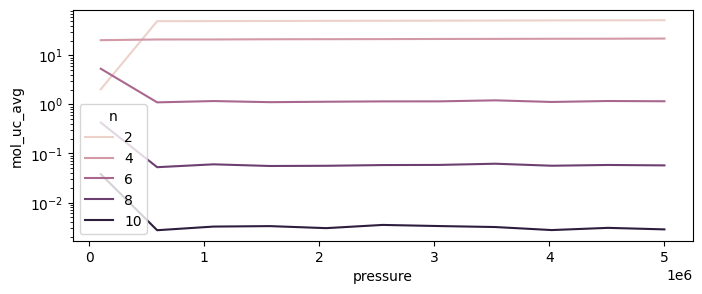

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(8, 3), dpi=100)

sns.lineplot(
    data=df.query('temperature == 300 and adsorption_type=="absolute"'),
    x='pressure',
    y='mol_uc_avg', hue='n')
ax.set_yscale('log')

# Make ml model

In [1]:
import pandas as pd
import numpy as np

data = pd.read_csv('../data/adsorption/adsorption_gcmc_dataset.csv')
data.head()

data['log_mol_uc_avg'] = data['mol_uc_avg'].apply(lambda x: -np.log10(np.abs(x)) if x < 0 else np.log10(x))
data['pressure_bar'] = data['pressure'] / 1e5
data['adsorption_type_num'] = data['adsorption_type'].map({'absolute': 0, 'excess': 1})

## Knn (works)

In [15]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
import joblib
from kinetic_model.constants.adsorption import AdsorptionKNN

# Example usage:
# 1) Fit and save model
ads_model = AdsorptionKNN(n_neighbors=2)
ads_model.fit(data, y_col='mol_uc_avg')
joblib.dump(ads_model, '../data/processed/knn_adsorption_model_test.pkl')

['../data/processed/knn_adsorption_model_test.pkl']

/tmp/ipykernel_7803/622185308.py:28: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(


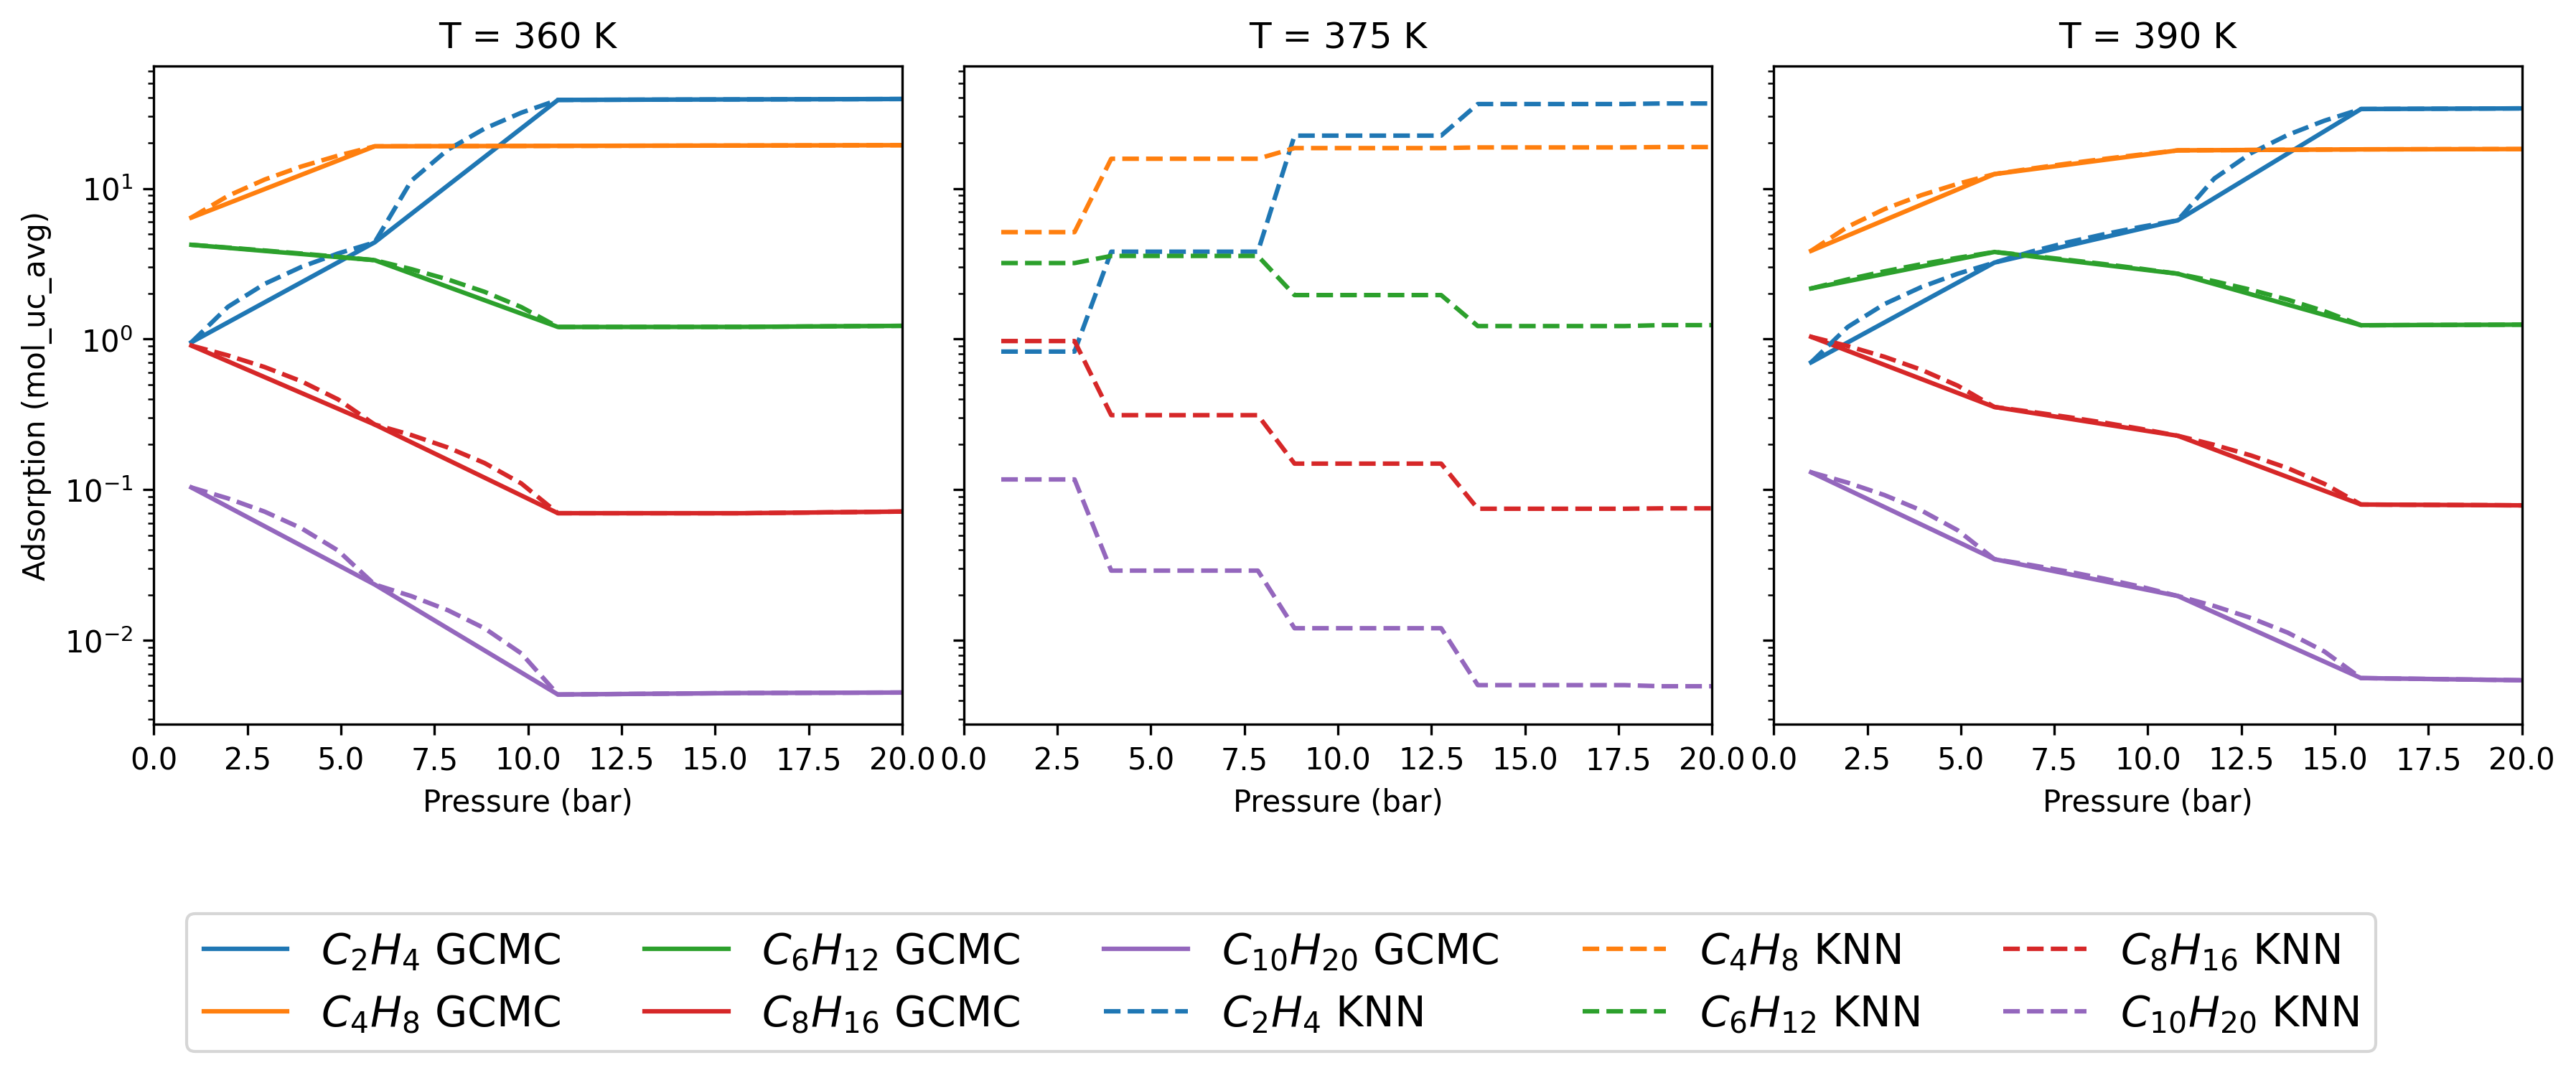

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# load your model and data
ads_model_loaded = joblib.load('../data/processed/knn_adsorption_model_test.pkl')

# define the six temperatures: 300, 330, 360, 390, 420, 450
# temps = [300 + 30 * i for i in range(5)]
# temps.append(410)
# temps.sort()
temps = [360, 375, 390]
# keep your same color‐mapping
palette = dict(zip(
    range(2, 11, 2),
    sns.color_palette('tab10', n_colors=5)
))

# set up a 2×3 figure
fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=300, sharex=True, sharey=True)
axes = axes.flatten()

# common pressure axis
m = 51
pressure = np.linspace(1, 50, m)

for ax, T in zip(axes, temps):
    # plot the existing data
    sns.lineplot(
        data=data.query(
            'temperature == @T and adsorption_type=="absolute"'
        ),
        x='pressure_bar', y='mol_uc_avg',
        hue='n', palette=palette,
        ax=ax
    )

    # compute and plot predictions
    for n_val in range(2, 11, 2):
        X_test = pd.DataFrame({
            'pressure_bar': pressure,
            'temperature': [T] * m,
            'n':           [n_val] * m,
            'adsorption_type_num': [0] * m
        })
        y_pred = ads_model_loaded(X_test)
        ax.plot(
            pressure, y_pred,
            color=palette[n_val],
            linestyle='--',
            label=f'pred (n={n_val})'
        )

    ax.set_yscale('log')
    ax.set_title(f'T = {T} K')
    ax.set_xlabel('Pressure (bar)')
    ax.set_ylabel('Adsorption (mol_uc_avg)')
    ax.legend(fontsize='small', loc='upper left')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend_.remove()
    ax.set_xlim(0, 20)

labels = [f'$C_{{{n}}}H_{{{2*n}}}$ GCMC' for n in range(2, 11, 2)]
labels += [f'$C_{{{n}}}H_{{{2*n}}}$ KNN' for n in range(2, 11, 2)]
fig.legend(
    handles=handles, labels=labels,
    title='',
    loc='upper center', bbox_to_anchor=(0.5, -0.05),
    ncol=5, fontsize=14
)
fig.tight_layout()
plt.show()

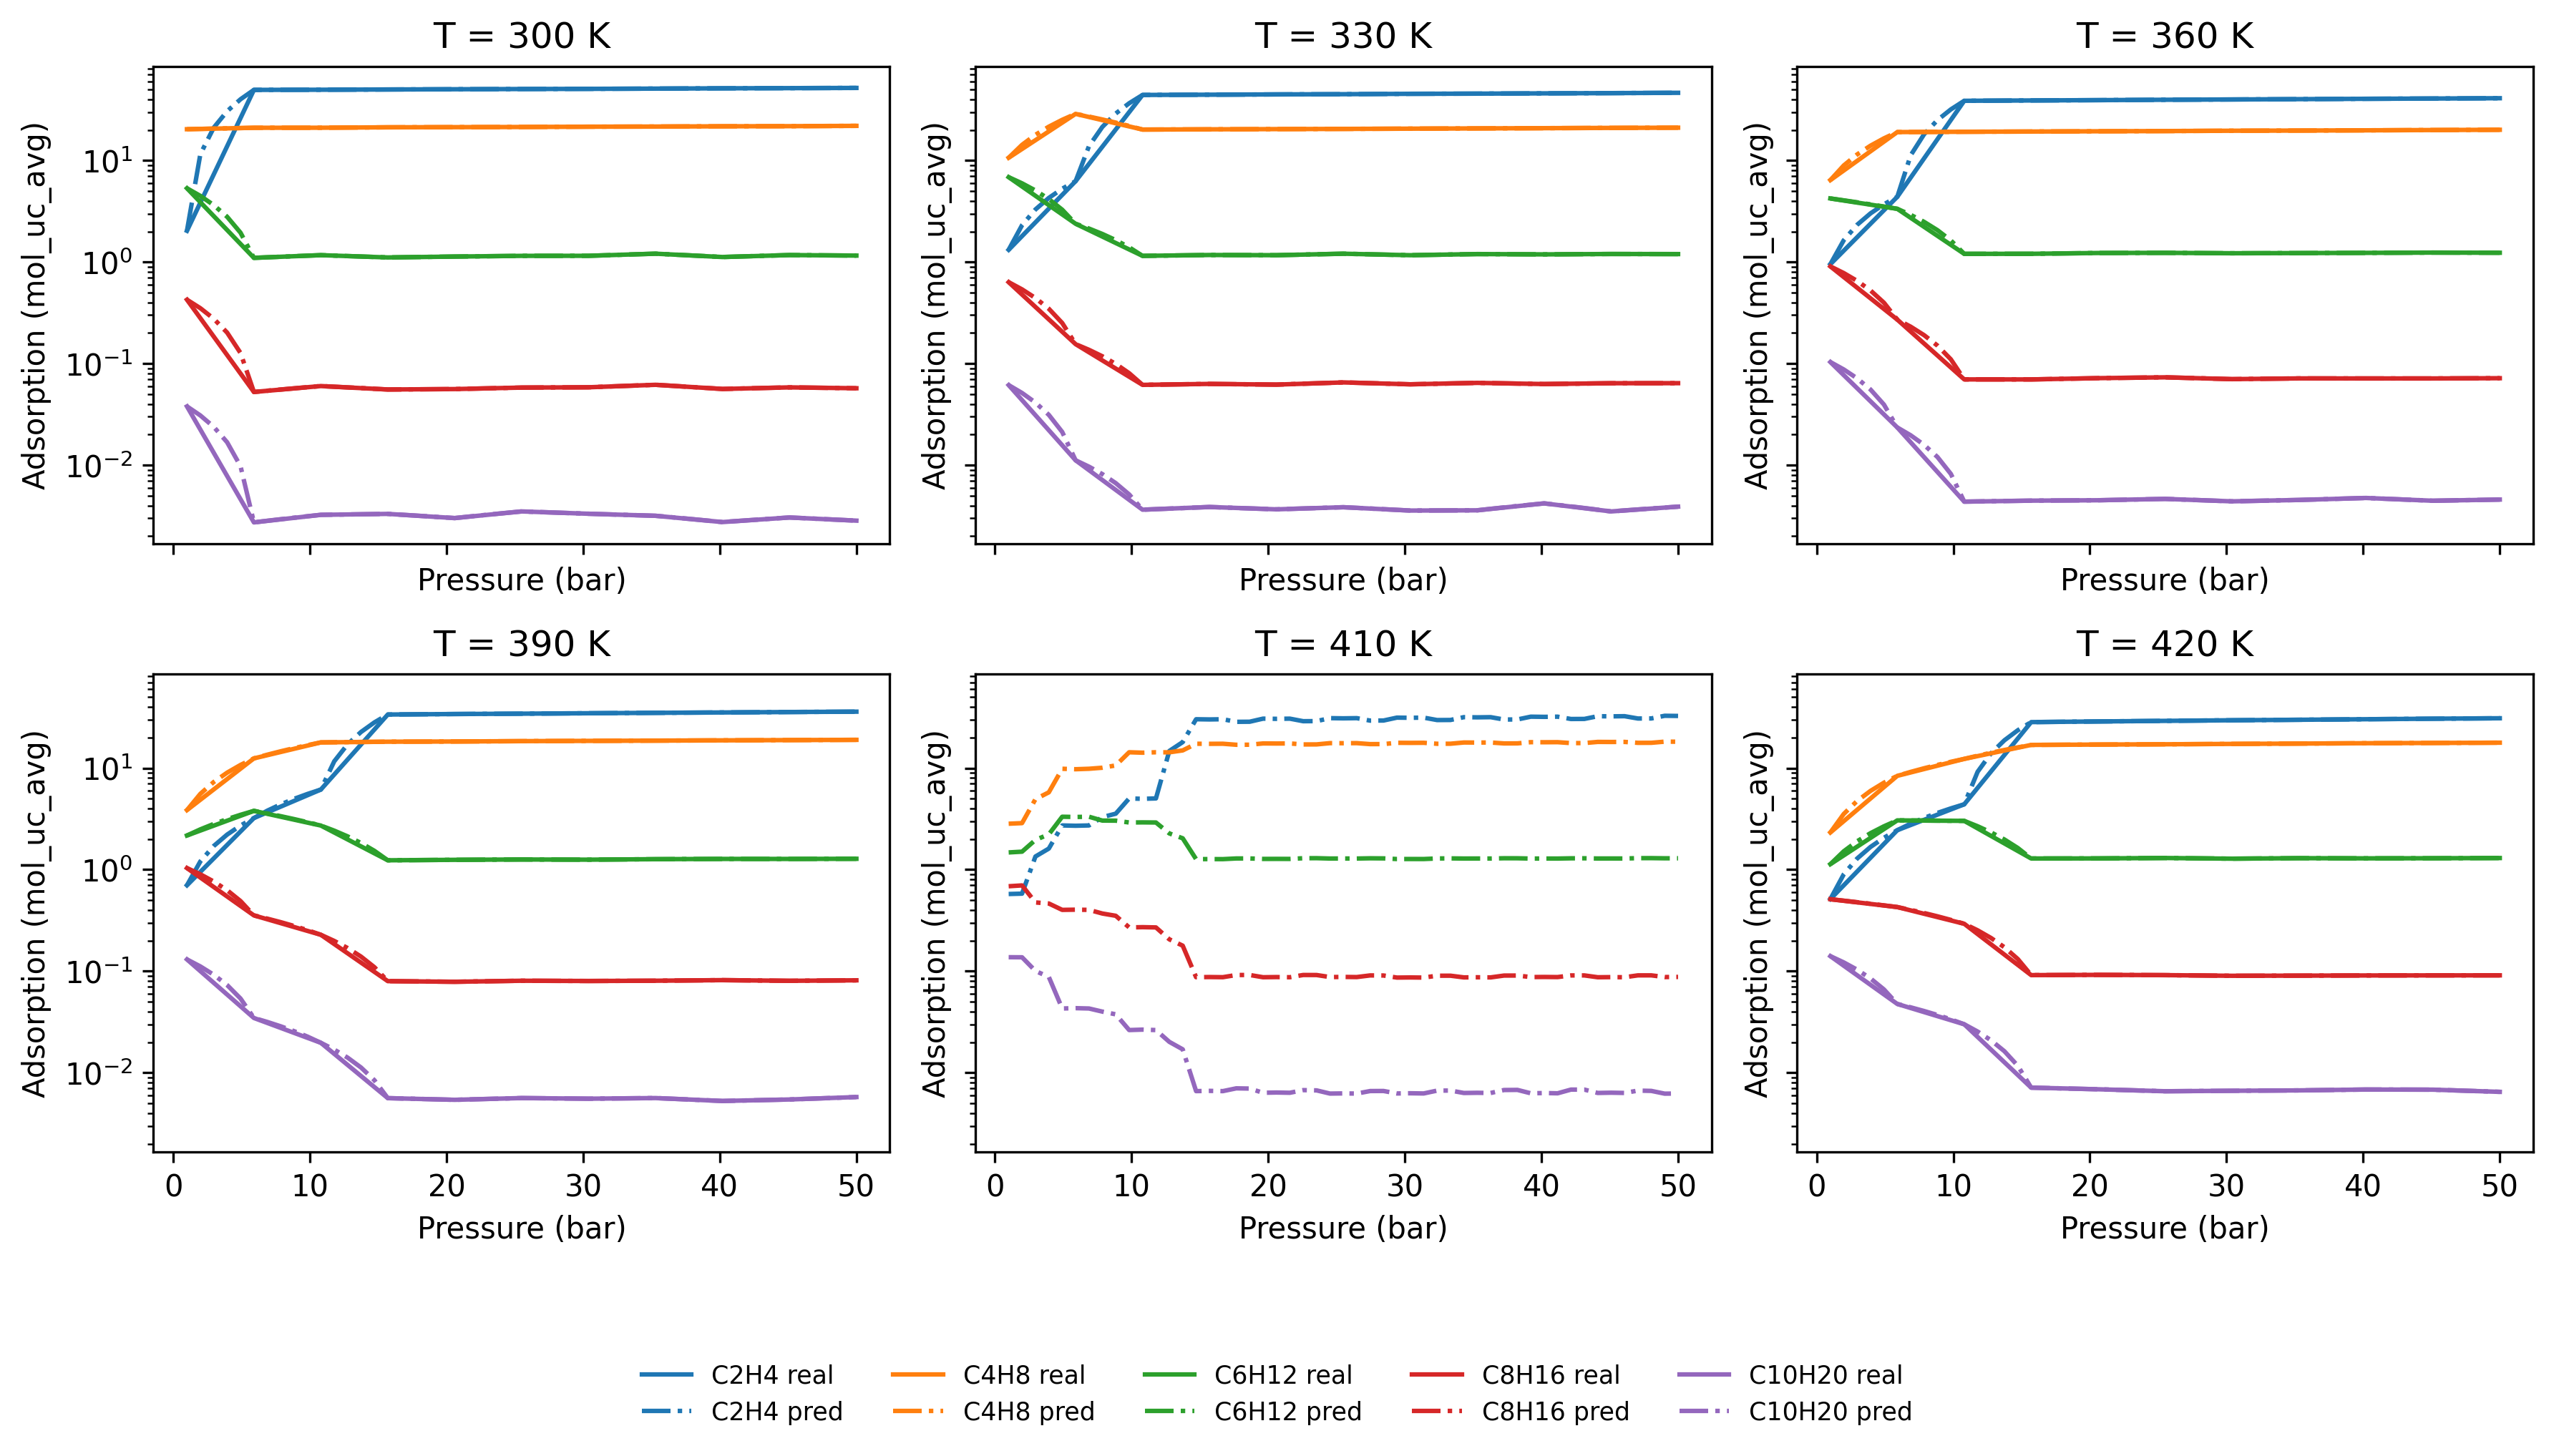

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import joblib

# --- load model & data ---
ads_model = joblib.load('../data/processed/knn_adsorption_model.pkl')
data = data.sort_values('pressure_bar')
# --- settings ---
temps   = sorted([300 + 30*i for i in range(5)] + [410])
palette = dict(zip(range(2, 11, 2), plt.get_cmap('tab10').colors))
species = {n: f'C{n}H{2*n}' for n in palette}
pressure = np.linspace(1, 50, 51)

# --- set up 2×3 grid ---
fig, axes = plt.subplots(2, 3, figsize=(12, 6), dpi=300,
                         sharex=True, sharey=True)
axes = axes.flatten()

for ax, T in zip(axes, temps):
    # for each molecule
    for n_val, col in palette.items():
        # real data
        df_sub = data.query(
            'temperature == @T and adsorption_type=="absolute" and n==@n_val'
        )
        ax.plot(df_sub.pressure_bar, df_sub.mol_uc_avg,
                linestyle='-', color=col)

        # model prediction
        Xtest = pd.DataFrame({
            'pressure_bar':       pressure,
            'temperature':        T,
            'n':                  n_val,
            'adsorption_type_num': 0
        })
        y_pred = ads_model.predict(Xtest)
        ax.plot(pressure, y_pred,
                linestyle='-.', color=col)

    ax.set_yscale('log')
    ax.set_title(f'T = {T} K')
    ax.set_xlabel('Pressure (bar)')
    ax.set_ylabel('Adsorption (mol_uc_avg)')

fig.tight_layout()

# --- build one figure‐level legend ---
handles, labels = [], []
for n_val, col in palette.items():
    name = species[n_val]
    handles += [
        Line2D([0], [0], color=col, linestyle='-'),
        Line2D([0], [0], color=col, linestyle='-.'),
    ]
    labels += [f'{name} real', f'{name} pred']

fig.legend(
    handles, labels,
    loc='upper center',
    ncol=len(palette),   # e.g. 5 columns for 5 species pairs
    frameon=False,
    fontsize='small',
    bbox_to_anchor=(0.5, -.05)
)

plt.show()


# Improve this model for prediction beyond $C_{10}H_{20}$

In [19]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
import joblib
from kinetic_model.constants.adsorption import AdsorptionKNN
# load your model and data
ads_model_loaded = joblib.load('../data/processed/knn_adsorption_model.pkl')


data = {'pressure_bar': [],
    'temperature': [],
    'n': [],
    'adsorption_type_num': []}

for n in range(2, 11, 2):
    for T in range(300, 601, 30):
        for p in range(1, 51):
            for ads_type in range(2):
                data['pressure_bar'].append(p)
                data['temperature'].append(T)
                data['n'].append(n)
                data['adsorption_type_num'].append(ads_type)

data = pd.DataFrame(data)
y_pred = ads_model_loaded(data)
data['mol_uc_avg'] = y_pred
data.head()

,pressure_bar,temperature,n,adsorption_type_num,mol_uc_avg
0,1,300,2,0,2.029520
1,1,300,2,1,1.933677
2,2,300,2,0,11.731506
3,2,300,2,1,8.014903
4,3,300,2,0,21.433491


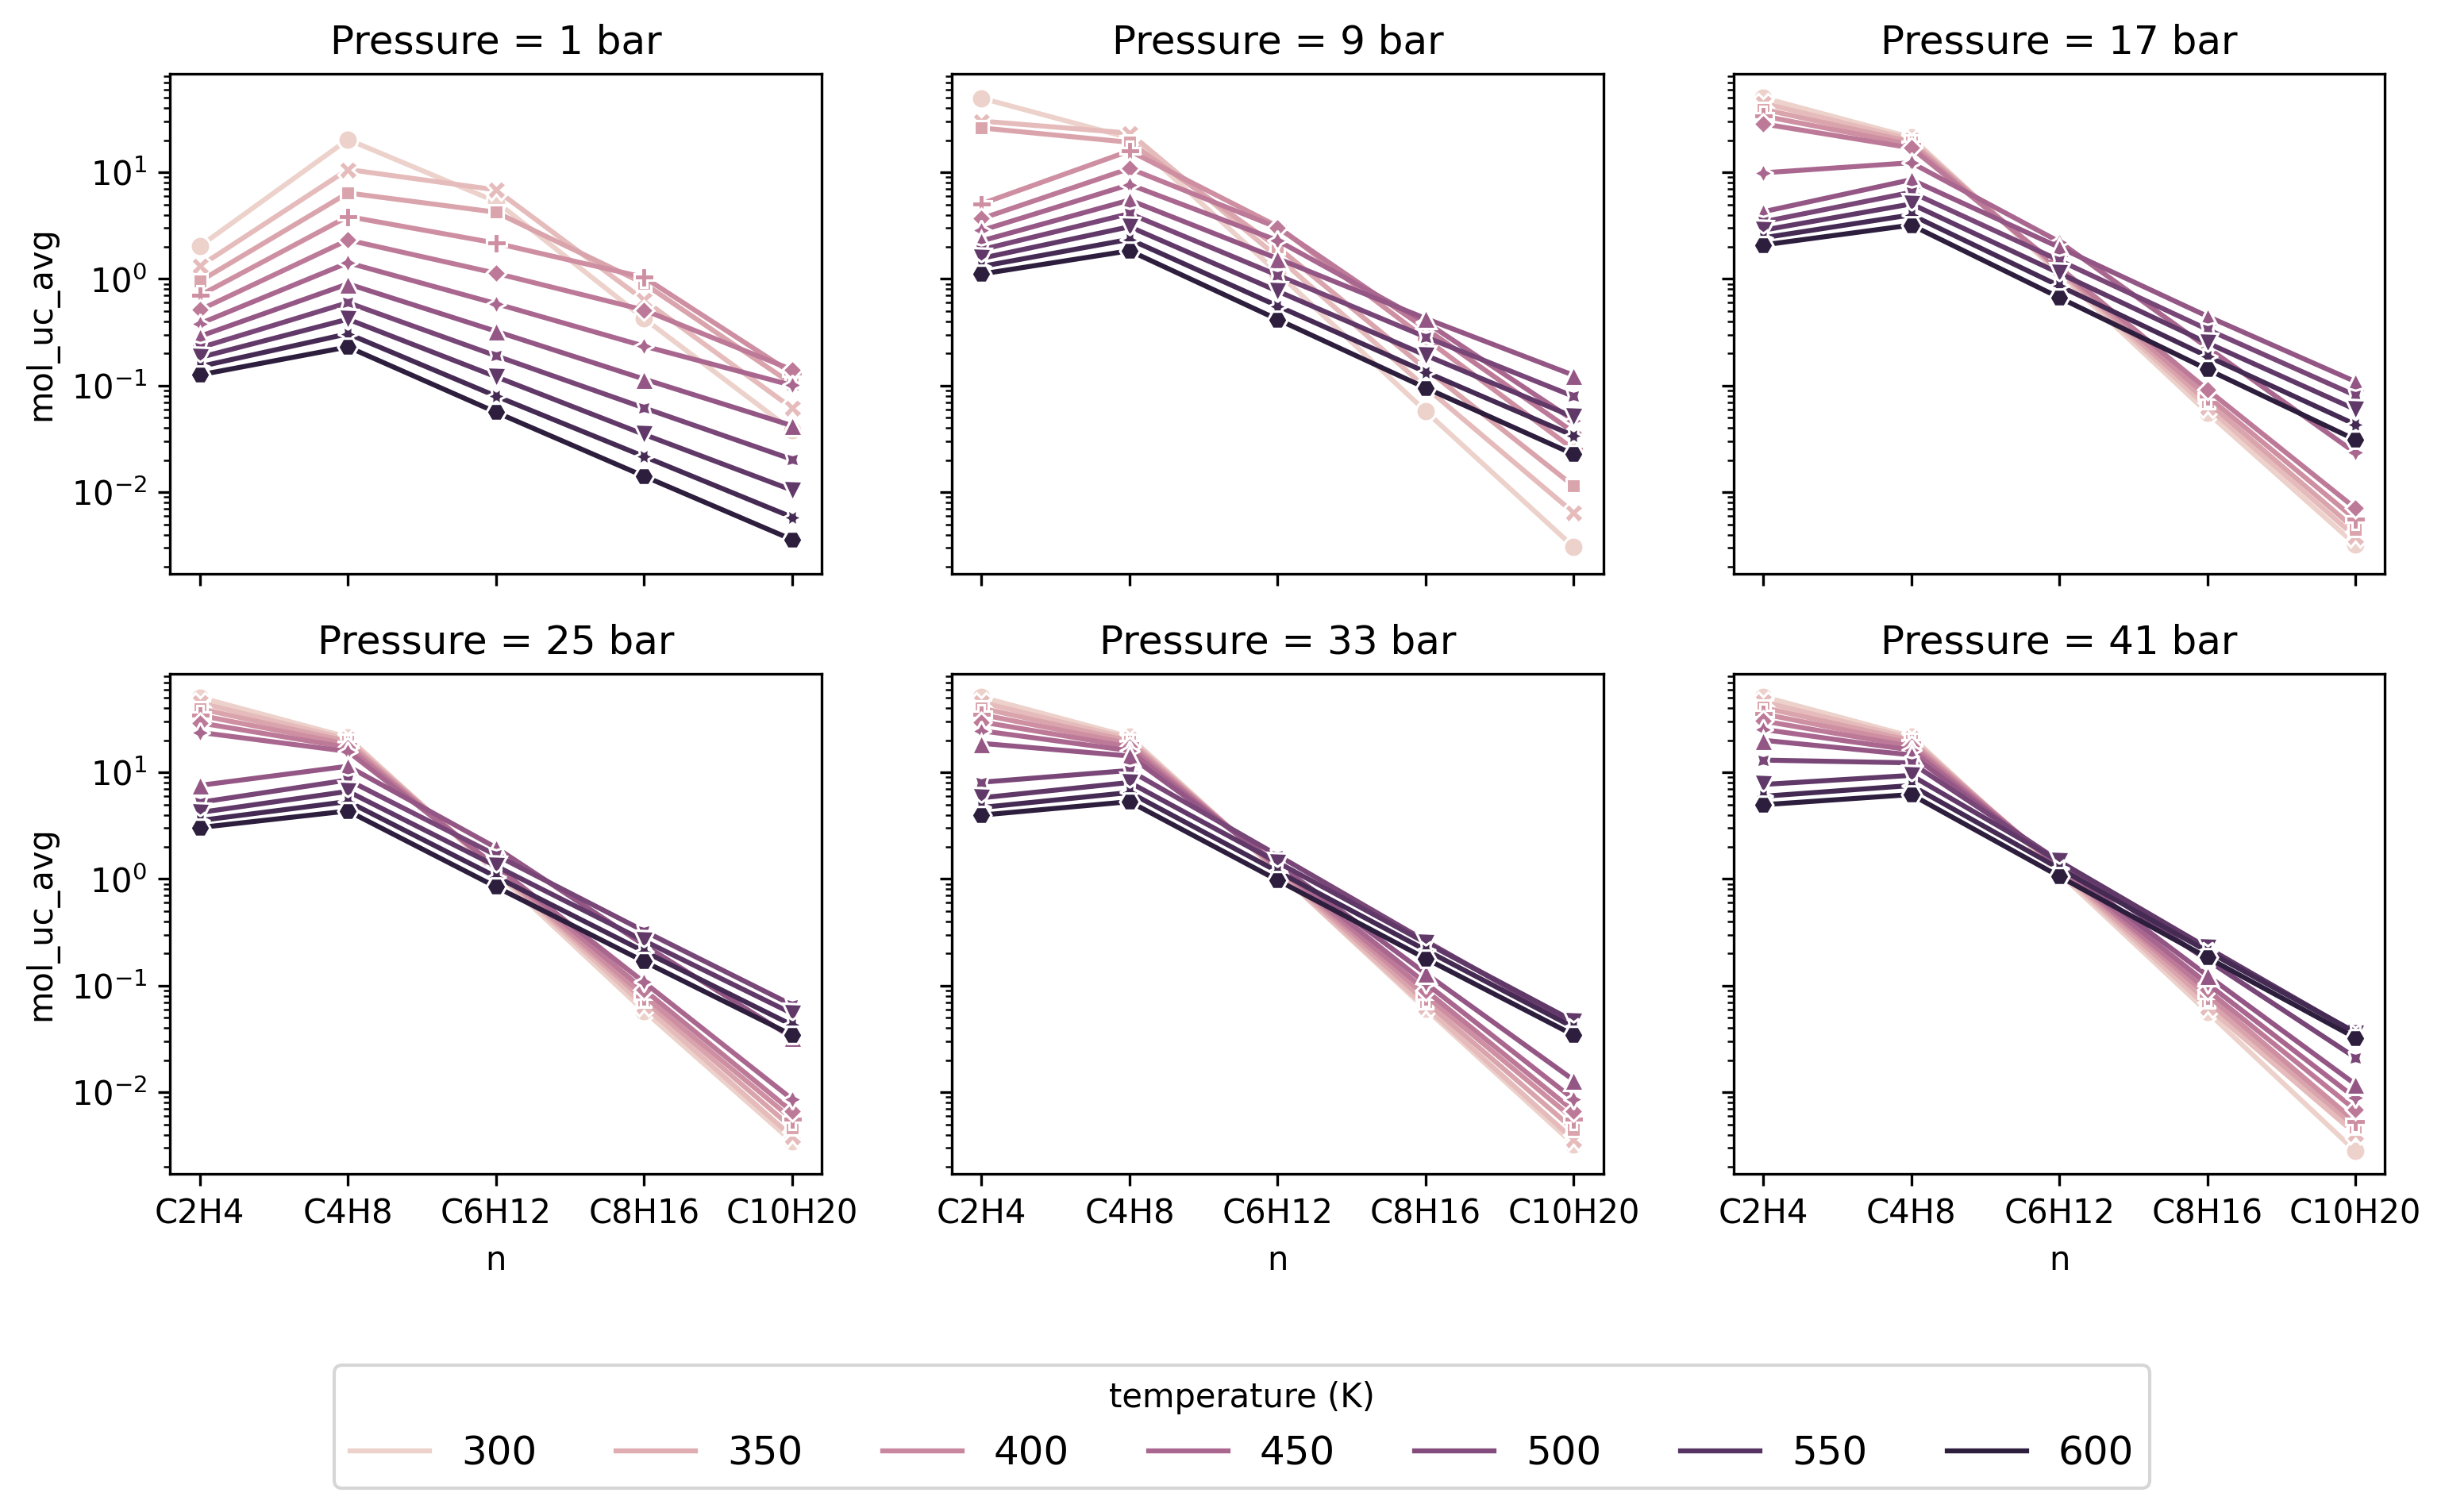

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axs = plt.subplots(2, 3, figsize=(12, 6), dpi=300, sharex=True, sharey=True)

for pressure, ax in zip(list(range(1, 51, 8)), axs.flatten()):
    sns.lineplot(data = data.query('pressure_bar == @pressure and adsorption_type_num == 0'),
                 x = 'n', y = 'mol_uc_avg', hue = 'temperature', style='temperature', markers=True, dashes=False, ax=ax)
    
    ax.set_yscale('log')
    ax.set_title(f'Pressure = {pressure} bar')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_xticks(
        ticks=range(2, 11, 2),
        labels=[f'C{n}H{2*n}' for n in range(2, 11, 2)]
    )

fig.legend(handles=handles[:7], labels=labels[:7], loc='upper center', 
           bbox_to_anchor=[0.5, -0.01], ncol=7, fontsize=12, title='temperature (K)')

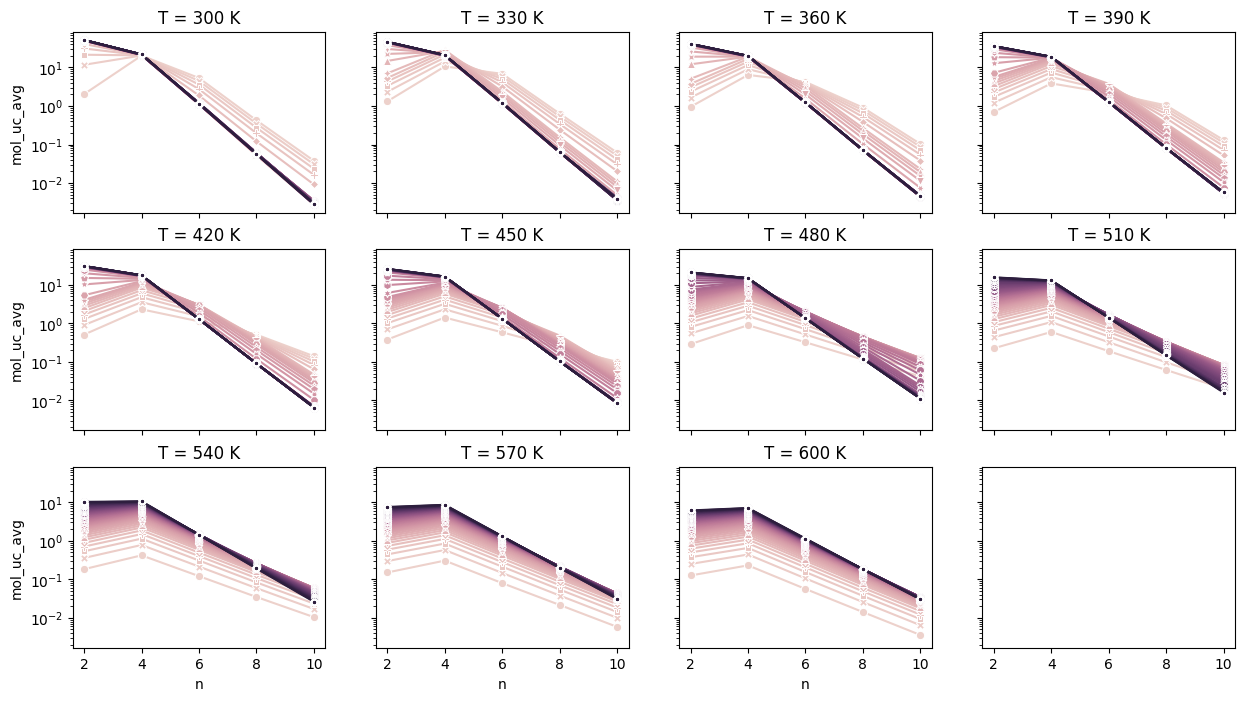

In [9]:
fig, axs = plt.subplots(3, 4, figsize=(15, 8), dpi=100, sharex=True, sharey=True)

for temperature, ax in zip(list(range(300, 601, 30)), axs.flatten()):
    sns.lineplot(data = data.query('adsorption_type_num == 0 and temperature == @temperature'),
                 x = 'n', y = 'mol_uc_avg', hue = 'pressure_bar', style='pressure_bar', 
                 markers=True, dashes=False, ax=ax)
    ax.set_yscale('log')
    ax.set_title(f'T = {temperature} K')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()

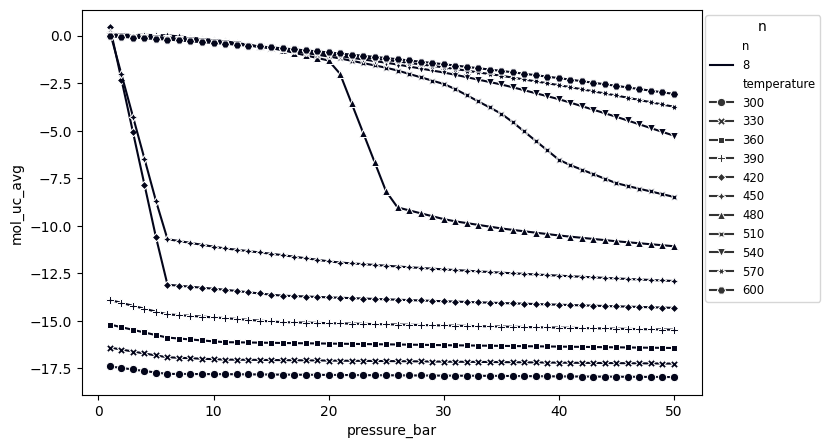

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(8, 5), dpi=100)

sns.lineplot(data=data.query('n == 8 and adsorption_type_num == 1'), 
                x='pressure_bar', y='mol_uc_avg', hue='n', 
                style='temperature', markers=True, dashes=False,
                ax=ax, palette='rocket')

ax.legend(title='n', fontsize='small', loc='upper right', bbox_to_anchor=(1.2, 1))

<Axes: xlabel='percentage_error', ylabel='Count'>

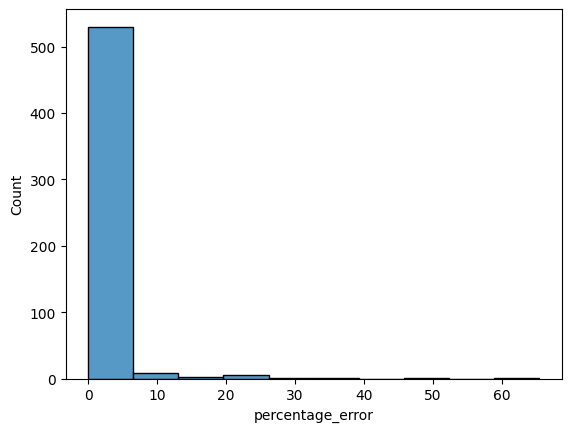

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso


def check_linearity(X_train, y_train, X_test, y_test):
    """
    Fit a linear regression model to the input data.

    Parameters
    ----------
    X : pandas.DataFrame or numpy.ndarray
        Feature matrix (shape: [n_samples, n_features])
    y : array-like
        Target values (shape: [n_samples])

    Returns
    -------
    model : sklearn.linear_model.LinearRegression
        Fitted linear regression model
    """
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))
    percentage_error = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
    return rmse, percentage_error


adsorption_type = 0

errors = []

for pressure in data.pressure_bar.unique():
    for temperature in data.temperature.unique():
        dft = data.query('pressure_bar == @pressure and temperature == @temperature and adsorption_type_num == @adsorption_type').copy()
        X_train = dft.loc[dft.n.between(6, 8), ['pressure_bar', 'temperature', 'n']]
        X_test = dft.loc[dft.n > 8, ['pressure_bar', 'temperature', 'n']]
        y_train = dft.loc[dft.n.between(6, 8), 'mol_uc_avg']
        y_train = np.log10(y_train)
        y_test = dft.loc[dft.n > 8, 'mol_uc_avg']
        y_test = np.log10(y_test)
        rmse, percentage_error = check_linearity(X_train, y_train, X_test, y_test)
        errors.append((pressure, temperature, rmse, percentage_error))

errors_df = pd.DataFrame(errors, columns=['pressure', 'temperature', 'rmse', 'percentage_error'])

sns.histplot(data=errors_df, x='percentage_error', bins=10)

In [12]:
big_errors = errors_df[errors_df.percentage_error > 10]
big_errors

,pressure,temperature,rmse,percentage_error
2,1,360,0.272867,27.707606
3,1,390,0.578628,65.439189
4,1,420,0.215477,25.291208
13,2,360,0.232357,21.933178
14,2,390,0.462256,48.413847
15,2,420,0.119750,13.087317
24,3,360,0.183697,15.980807
25,3,390,0.346157,33.312615
36,4,390,0.226675,19.816959
38,4,450,0.145638,13.019184


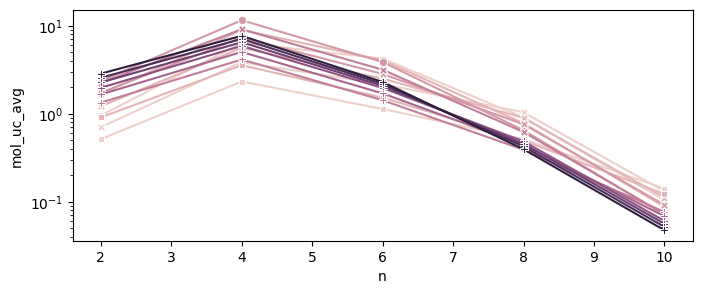

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(8, 3), dpi=100)

big_deviation = []
for pressure, temperature in zip(big_errors.pressure, big_errors.temperature):
    dft = data.query('pressure_bar == @pressure and temperature == @temperature and adsorption_type_num == @adsorption_type').copy()
    big_deviation.append(dft)
big_deviation = pd.concat(big_deviation)

sns.lineplot(data=big_deviation, x='n', y='mol_uc_avg', hue='pressure_bar', style='temperature', markers=True, dashes=False, ax=ax)
ax.set_yscale('log')
ax.legend().remove()

## Try

In [14]:
from kinetic_model.constants.adsorption import AdsorptionKNN, AdsorptionKNNSlopeExtrap

import numpy as np
import pandas as pd


ads_model = AdsorptionKNNSlopeExtrap(n_neighbors=2)
ads_model.fit(data, y_col='mol_uc_avg')
joblib.dump(ads_model, '../data/processed/knn_adsorption_slope_model.pkl')

['../data/processed/knn_adsorption_slope_model.pkl']

In [15]:
pressure = 20
temperature = 330
ads_type_num = 1
dft = data.query('pressure_bar == @pressure and temperature == @temperature and adsorption_type_num == @ads_type_num').copy()

dft = pd.concat([
    dft,
    pd.DataFrame({
        'pressure_bar': [pressure] * 5,
        'temperature': [temperature] * 5,
        'n': range(12, 21, 2),
        'adsorption_type_num': [ads_type_num] * 5
    })
])

predicted = ads_model(dft)
dft['predicted'] = predicted
dft

,pressure_bar,temperature,n,adsorption_type_num,mol_uc_avg,predicted
139,20,330,2,1,27.564986,27.564986
1239,20,330,4,1,3.210585,3.210585
2339,20,330,6,1,-15.977856,-15.977856
3439,20,330,8,1,-17.083991,-17.083991
4539,20,330,10,1,-17.142491,-17.142491
0,20,330,12,1,NaN,-17.142491
1,20,330,14,1,NaN,-17.142491
2,20,330,16,1,NaN,-17.142491
3,20,330,18,1,NaN,-17.142491
4,20,330,20,1,NaN,-17.142491


In [16]:
ads_model = joblib.load('../data/processed/knn_adsorption_slope_model.pkl')
data_extended = pd.concat([
    data,
    data.assign(n=data['n'] + 10)])

data_extended['mol_uc_avg'] = ads_model(data_extended)

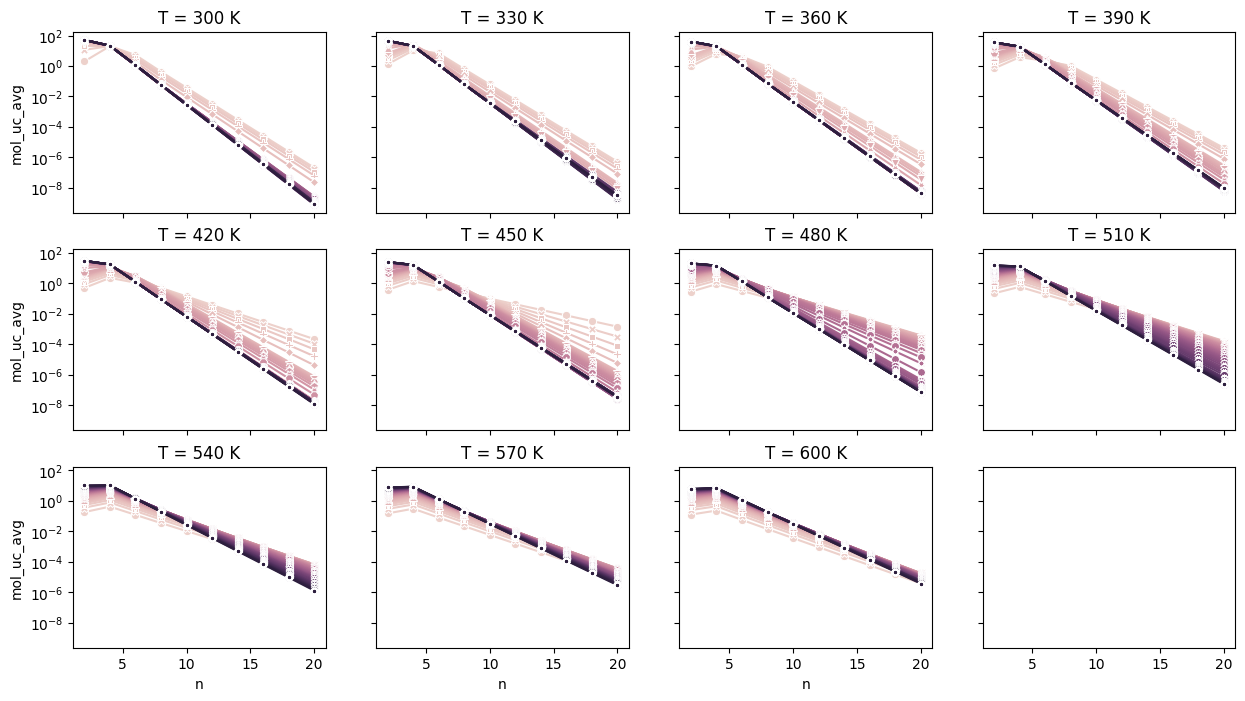

In [17]:
fig, axs = plt.subplots(3, 4, figsize=(15, 8), dpi=100, sharex=True, sharey=True)

for temperature, ax in zip(list(range(300, 601, 30)), axs.flatten()):
    sns.lineplot(data = data_extended.query('adsorption_type_num == 0 and temperature == @temperature'),
                 x = 'n', y = 'mol_uc_avg', hue = 'pressure_bar', style='pressure_bar', 
                 markers=True, dashes=False, ax=ax)
    ax.set_yscale('log')
    ax.set_title(f'T = {temperature} K')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()

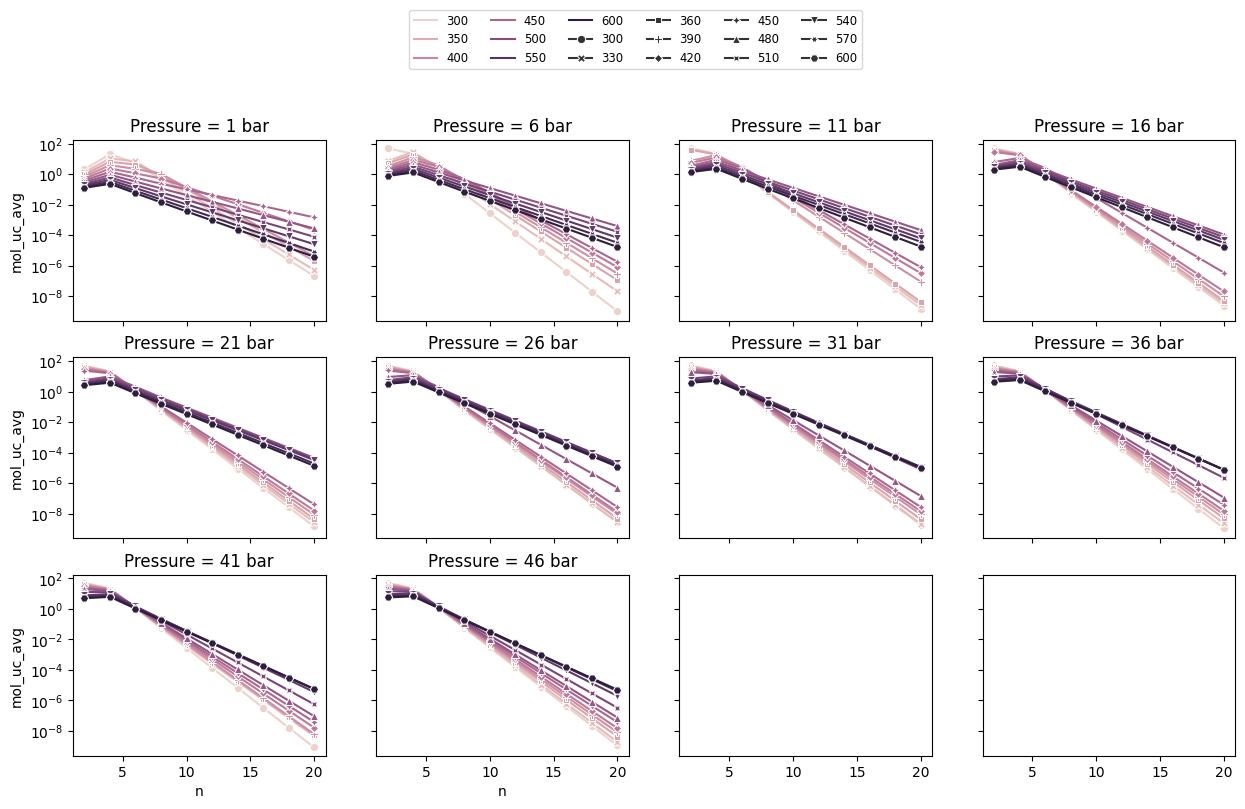

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axs = plt.subplots(3, 4, figsize=(15, 8), dpi=100, sharex=True, sharey=True)

for pressure, ax in zip(list(range(1, 51, 5)), axs.flatten()):
    sns.lineplot(data = data_extended.query('pressure_bar == @pressure and adsorption_type_num == 0'),
                 x = 'n', y = 'mol_uc_avg', hue = 'temperature', style='temperature', markers=True, dashes=False, ax=ax)
    
    ax.set_yscale('log')
    ax.set_title(f'Pressure = {pressure} bar')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()

fig.legend(handles=handles, labels=labels, loc='upper center', 
           bbox_to_anchor=[0.5, 1.05], ncol=6, fontsize='small')